In [0]:
catalog = "databricks_rr"
schema = "default"
volume = "capstone"
base_path = f"/Volumes/{catalog}/{schema}/{volume}/water_network"

spark.sql(f"USE CATALOG {catalog}")
spark.sql(f"USE SCHEMA {schema}")

print(f"Catalog & Schema set to: {catalog}.{schema}")
print(f"Source Files Volume Path: {base_path}")


Catalog & Schema set to: databricks_rr.default
Source Files Volume Path: /Volumes/databricks_rr/default/capstone/water_network


In [0]:
display(dbutils.fs.ls(base_path))


path,name,size,modificationTime
dbfs:/Volumes/databricks_rr/default/capstone/water_network/entries_parquet_backup/,entries_parquet_backup/,0,1795155336000
dbfs:/Volumes/databricks_rr/default/capstone/water_network/water_meter_readings.csv,water_meter_readings.csv,11125,1795155657000
dbfs:/Volumes/databricks_rr/default/capstone/water_network/water_reading_changes.csv,water_reading_changes.csv,956,1795155657000
dbfs:/Volumes/databricks_rr/default/capstone/water_network/water_readings_incremental.csv,water_readings_incremental.csv,1391,1795155657000
dbfs:/Volumes/databricks_rr/default/capstone/water_network/water_service_requests.csv,water_service_requests.csv,2662,1795155657000
dbfs:/Volumes/databricks_rr/default/capstone/water_network/water_zones.json,water_zones.json,2343,1795155657000


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, StringType, DoubleType, TimestampType

reading_schema = StructType([
    StructField("reading_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reading_time", TimestampType(), True),
    StructField("flow_lpm", DoubleType(), True),
    StructField("pressure_bar", DoubleType(), True),
    StructField("chlorine_mg_l", DoubleType(), True),
    StructField("consumption_liters", IntegerType(), True),
    StructField("reading_status", StringType(), True),
    StructField("source_system", StringType(), True)
])

def load_readings(file_name):
    return (spark.read.format("csv")
            .option("header", "true")
            .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
            .schema(reading_schema)
            .load(f"{base_path}/{file_name}"))

source_df = load_readings("water_meter_readings.csv")
source_df.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable("water_meter_readings_source")
source_df.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable("water_meter_readings_work")

changes_df = load_readings("water_reading_changes.csv")
changes_df.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable("water_reading_changes")

inc_staging_df = load_readings("water_readings_incremental.csv")
inc_staging_df.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable("water_readings_incremental_staging")

zone_raw = spark.read.json(f"{base_path}/water_zones.json")
zone_raw.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable("water_zones_raw")

zone_flat = zone_raw.select(
    "zone_id",
    "zone_name",
    F.col("location.city").alias("city"),
    F.col("location.district").alias("district"),
    "zone_type",
    "daily_capacity_liters",
    "active",
    "commissioned_on"
)
zone_flat.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable("water_zones")

request_schema = StructType([
    StructField("request_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reported_at", TimestampType(), True),
    StructField("issue_type", StringType(), True),
    StructField("priority", StringType(), True),
    StructField("estimated_cost", DoubleType(), True),
    StructField("work_status", StringType(), True)
])

requests_df = (spark.read.format("csv")
               .option("header", "true")
               .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
               .schema(request_schema)
               .load(f"{base_path}/water_service_requests.csv"))
requests_df.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable("water_service_requests")

print("All setup Delta tables successfully created.")


All setup Delta tables successfully created.


## Section A | SQL Querying and Filtering


In [0]:
# 01. Inspect water_meter_readings_source and display its schema and total row count.
display(spark.sql("DESCRIBE TABLE water_meter_readings_source"))
display(spark.sql("SELECT COUNT(*) AS total_rows FROM water_meter_readings_source"))


col_name,data_type,comment
reading_id,int,null
meter_id,string,null
zone_id,string,null
reading_time,timestamp,null
flow_lpm,double,null
pressure_bar,double,null
chlorine_mg_l,double,null
consumption_liters,int,null
reading_status,string,null
source_system,string,null


total_rows
157


In [0]:
# 02. Retrieve reading_id, meter_id, zone_id, reading_time and consumption_liters for readings marked Valid.
display(spark.sql("""
SELECT reading_id, meter_id, zone_id, reading_time, consumption_liters
FROM water_meter_readings_source
WHERE reading_status = 'Valid'
"""))


reading_id,meter_id,zone_id,reading_time,consumption_liters
1001,M001,W01,2026-10-01T07:00:00.000Z,2365
1002,M002,W02,2026-10-01T08:10:00.000Z,3545
1003,M003,W03,2026-10-01T09:20:00.000Z,548
1004,M004,W04,2026-10-01T10:00:00.000Z,2871
1006,M006,W06,2026-10-01T12:20:00.000Z,2171
1007,M007,W07,2026-10-01T13:00:00.000Z,4167
1008,M008,W08,2026-10-01T14:10:00.000Z,3621
1009,M009,W09,2026-10-01T15:20:00.000Z,1609
1010,M010,W10,2026-10-01T16:00:00.000Z,1829
1011,M011,W01,2026-10-02T07:10:00.000Z,313


In [0]:
# 03. Find readings where pressure_bar is below 2.5, ordering the results from lowest pressure upward.
display(spark.sql("""
SELECT *
FROM water_meter_readings_source
WHERE pressure_bar < 2.5
ORDER BY pressure_bar ASC
"""))


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1071,M011,W01,2026-10-08T07:10:00.000Z,10.9,1.8,0.8,647,Valid,SmartMeter
1064,M004,W04,2026-10-07T10:00:00.000Z,20.3,1.82,0.84,708,Valid,Gateway
1024,M024,W04,2026-10-03T10:20:00.000Z,44.5,1.83,1.25,2085,Valid,FieldApp
1116,M026,W06,2026-10-12T12:10:00.000Z,28.9,1.84,0.36,1692,Valid,SmartMeter
1133,M013,W03,2026-10-14T09:00:00.000Z,15.6,1.86,0.8,900,Valid,Gateway
1028,M028,W08,2026-10-03T14:00:00.000Z,15.0,1.9,0.94,452,Valid,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1051,M021,W01,2026-10-06T07:20:00.000Z,72.0,1.93,0.27,1818,Valid,FieldApp
1052,M022,W02,2026-10-06T08:00:00.000Z,74.0,1.94,0.21,4669,Valid,Gateway
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter


In [0]:
# 04. Find records where flow_lpm is between 20 and 50 and the source_system is Gateway or SmartMeter.
display(spark.sql("""
SELECT *
FROM water_meter_readings_source
WHERE flow_lpm BETWEEN 20 AND 50
  AND source_system IN ('Gateway', 'SmartMeter')
"""))


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1014,M014,W04,2026-10-02T10:10:00.000Z,22.4,4.73,0.5,1108,Valid,SmartMeter
1017,M017,W07,2026-10-02T13:10:00.000Z,28.0,3.77,1.08,1318,Valid,SmartMeter
1019,M019,W09,2026-10-02T15:00:00.000Z,23.0,4.34,0.28,1091,Valid,Gateway
1022,M022,W02,2026-10-03T08:00:00.000Z,32.5,3.35,0.6,1706,Suspect,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1047,M017,W07,2026-10-05T13:10:00.000Z,28.8,3.23,0.91,1258,Valid,SmartMeter
1049,M019,W09,2026-10-05T15:00:00.000Z,21.4,2.43,0.47,611,Valid,Gateway
1050,M020,W10,2026-10-05T16:10:00.000Z,37.2,3.91,1.02,2154,Valid,SmartMeter
1056,M026,W06,2026-10-06T12:10:00.000Z,27.2,2.69,0.68,1131,Suspect,SmartMeter


In [0]:
# 05. List distinct reading_status values and count how many readings belong to each status.
display(spark.sql("""
SELECT reading_status, COUNT(*) AS reading_count
FROM water_meter_readings_source
GROUP BY reading_status
ORDER BY reading_count DESC
"""))


reading_status,reading_count
Valid,137
Suspect,11
Rejected,9


## Section B | Joins, Aggregations and Window Functions


In [0]:
# 06. Join meter readings with water_zones and show zone_name, district, meter_id and consumption_liters.
display(spark.sql("""
SELECT z.zone_name, z.district, r.meter_id, r.consumption_liters
FROM water_meter_readings_source r
JOIN water_zones z ON r.zone_id = z.zone_id
"""))


zone_name,district,meter_id,consumption_liters
Old City,Central,M001,2365
Hill View,North,M002,3545
Market District,Central,M003,548
Lake Side,West,M004,2871
University Quarter,East,M005,2656
Industrial Estate,South,M006,2171
Garden Colony,North,M007,4167
Transit Hub,East,M008,3621
Riverfront,West,M009,1609
South Extension,South,M010,1829


In [0]:
# 07. Find reading records whose zone_id has no matching entry in water_zones.
display(spark.sql("""
SELECT r.*
FROM water_meter_readings_source r
LEFT ANTI JOIN water_zones z ON r.zone_id = z.zone_id
"""))


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1154,M999,W99,2026-10-16T11:00:00.000Z,24.5,3.0,0.45,1150,Valid,FieldApp
1156,M012,null,2026-10-16T12:30:00.000Z,28.0,3.1,0.52,870,Valid,Gateway


In [0]:
# 08. Find zones that currently have no meter readings, using a suitable join.
display(spark.sql("""
SELECT z.zone_id, z.zone_name, z.zone_type
FROM water_zones z
LEFT ANTI JOIN water_meter_readings_source r ON z.zone_id = r.zone_id
"""))


zone_id,zone_name,zone_type
W11,New Development,Mixed


In [0]:
# 09. Calculate total valid consumption, average pressure and reading count for each zone; exclude nonpositive consumption.
display(spark.sql("""
SELECT r.zone_id,
       z.zone_name,
       SUM(r.consumption_liters) AS total_valid_consumption,
       ROUND(AVG(r.pressure_bar), 2) AS avg_pressure,
       COUNT(*) AS reading_count
FROM water_meter_readings_source r
LEFT JOIN water_zones z ON r.zone_id = z.zone_id
WHERE r.reading_status = 'Valid' AND r.consumption_liters > 0
GROUP BY r.zone_id, z.zone_name
ORDER BY r.zone_id
"""))


zone_id,zone_name,total_valid_consumption,avg_pressure,reading_count
null,null,870,3.1,1
W01,Old City,23107,3.42,13
W02,Hill View,24120,3.31,13
W03,Market District,35665,3.02,13
W04,Lake Side,20781,3.24,14
W05,University Quarter,28717,3.63,14
W06,Industrial Estate,20212,3.16,13
W07,Garden Colony,25104,3.57,13
W08,Transit Hub,33689,2.87,14
W09,Riverfront,20894,3.55,13


In [0]:
# 10. Rank meters by total valid consumption within each district using a SQL window function.
display(spark.sql("""
WITH meter_totals AS (
  SELECT z.district, r.meter_id, SUM(r.consumption_liters) AS total_valid_consumption
  FROM water_meter_readings_source r
  JOIN water_zones z ON r.zone_id = z.zone_id
  WHERE r.reading_status = 'Valid' AND r.consumption_liters > 0
  GROUP BY z.district, r.meter_id
)
SELECT district, meter_id, total_valid_consumption,
       RANK() OVER (PARTITION BY district ORDER BY total_valid_consumption DESC) AS consumption_rank
FROM meter_totals
ORDER BY district, consumption_rank
"""))


district,meter_id,total_valid_consumption,consumption_rank
Central,M023,17814,1
Central,M001,11416,2
Central,M003,10447,3
Central,M013,7404,4
Central,M021,7395,5
Central,M011,4296,6
East,M008,14095,1
East,M018,10660,2
East,M025,10536,3
East,M015,9807,4


## Section C | PySpark DataFrame Operations


In [0]:
# 11. Load the meter readings and zone master Delta tables into separate PySpark DataFrames; print their schemas.
from pyspark.sql import functions as F

readings_df = spark.table("water_meter_readings_source")
zones_df = spark.table("water_zones")

print("--- water_meter_readings_source Schema ---")
readings_df.printSchema()

print("--- water_zones Schema ---")
zones_df.printSchema()


--- water_meter_readings_source Schema ---
root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

--- water_zones Schema ---
root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- district: string (nullable = true)
 |-- zone_type: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)



In [0]:
# 12. Use select(), filter() and orderBy() to display high-flow Valid readings.
high_flow_df = (
    readings_df
    .select("reading_id", "meter_id", "zone_id", "reading_time", "flow_lpm", "reading_status")
    .filter((F.col("reading_status") == "Valid") & (F.col("flow_lpm") >= 60))
    .orderBy(F.col("flow_lpm").desc())
)
display(high_flow_df)


reading_id,meter_id,zone_id,reading_time,flow_lpm,reading_status
1110,M020,W10,2026-10-11T16:10:00.000Z,84.0,Valid
1106,M016,W06,2026-10-11T12:00:00.000Z,83.9,Valid
1083,M023,W03,2026-10-09T09:10:00.000Z,83.9,Valid
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,Valid
1013,M013,W03,2026-10-02T09:00:00.000Z,80.7,Valid
1078,M018,W08,2026-10-08T14:20:00.000Z,80.7,Valid
1093,M003,W03,2026-10-10T09:20:00.000Z,80.4,Valid
1031,M001,W01,2026-10-04T07:00:00.000Z,80.1,Valid
1123,M003,W03,2026-10-13T09:20:00.000Z,79.7,Valid
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,Valid


In [0]:
# 13. Add a flow_category column: High for flow_lpm >= 60, Medium for 30 to below 60, Low otherwise; handle nulls explicitly.
flow_cat_df = readings_df.withColumn(
    "flow_category",
    F.when(F.col("flow_lpm").isNull(), "Unknown")
     .when(F.col("flow_lpm") >= 60, "High")
     .when(F.col("flow_lpm") >= 30, "Medium")
     .otherwise("Low")
)
display(flow_cat_df.groupBy("flow_category").count().orderBy("flow_category"))


flow_category,count
High,45
Low,44
Medium,68


In [0]:
# 14. Join the DataFrames and calculate average flow_lpm for each zone_type.
zone_type_flow_df = (
    readings_df.join(zones_df, "zone_id", "inner")
    .groupBy("zone_type")
    .agg(
        F.round(F.avg("flow_lpm"), 2).alias("avg_flow_lpm"),
        F.count("*").alias("reading_count")
    )
    .orderBy("zone_type")
)
display(zone_type_flow_df)


zone_type,avg_flow_lpm,reading_count
Commercial,56.1,30
Industrial,43.14,16
Institutional,49.33,16
Mixed,38.17,32
Residential,45.16,61


In [0]:
# 15. Use PySpark groupBy() and agg() to identify the three zones with the highest valid water consumption.
top3_zones_df = (
    readings_df
    .filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0))
    .groupBy("zone_id")
    .agg(F.sum("consumption_liters").alias("total_valid_consumption"))
    .join(zones_df.select("zone_id", "zone_name"), "zone_id", "inner")
    .orderBy(F.col("total_valid_consumption").desc())
    .limit(3)
)
display(top3_zones_df)


zone_id,total_valid_consumption,zone_name
W03,35665,Market District
W08,33689,Transit Hub
W05,28717,University Quarter


## Section D | Data Quality and Cleaning


In [0]:
# 16. Identify duplicate reading_id values and display every row associated with those IDs.
display(spark.sql("""
SELECT *
FROM water_meter_readings_source
WHERE reading_id IN (
  SELECT reading_id
  FROM water_meter_readings_source
  GROUP BY reading_id
  HAVING COUNT(*) > 1
)
ORDER BY reading_id, reading_time
"""))


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter
1044,M014,W04,2026-10-16T13:00:00.000Z,36.0,3.2,0.8,1300,Valid,Gateway


In [0]:
# 17. Find missing pressure_bar and source_system values and count the affected records.
display(spark.sql("""
SELECT SUM(CASE WHEN pressure_bar IS NULL THEN 1 ELSE 0 END) AS missing_pressure,
       SUM(CASE WHEN source_system IS NULL THEN 1 ELSE 0 END) AS missing_source_system,
       SUM(CASE WHEN pressure_bar IS NULL OR source_system IS NULL THEN 1 ELSE 0 END) AS total_affected_records
FROM water_meter_readings_source
"""))


missing_pressure,missing_source_system,total_affected_records
1,1,2


In [0]:
# 18. Identify invalid measurements: negative flow_lpm, nonpositive consumption_liters or missing zone_id.
display(spark.sql("""
SELECT reading_id, meter_id, zone_id, flow_lpm, consumption_liters, reading_status,
       CASE WHEN flow_lpm < 0 THEN 'Negative flow_lpm'
            WHEN consumption_liters <= 0 THEN 'Nonpositive consumption_liters'
            WHEN zone_id IS NULL THEN 'Missing zone_id'
       END AS invalid_reason
FROM water_meter_readings_source
WHERE flow_lpm < 0 OR consumption_liters <= 0 OR zone_id IS NULL
"""))


reading_id,meter_id,zone_id,flow_lpm,consumption_liters,reading_status,invalid_reason
1151,M004,W04,-12.5,500,Suspect,Negative flow_lpm
1152,M015,W05,22.0,0,Valid,Nonpositive consumption_liters
1156,M012,null,28.0,870,Valid,Missing zone_id


In [0]:
# 19. Create water_readings_clean as a new Delta table containing one row per reading_id, with Valid status and positive measurements; document the duplicate-selection rule.
# Duplicate-selection rule: Keep latest record by reading_time using ROW_NUMBER() OVER (PARTITION BY reading_id ORDER BY reading_time DESC).
spark.sql("""
CREATE OR REPLACE TABLE water_readings_clean
USING DELTA
AS
SELECT reading_id, meter_id, zone_id, reading_time, flow_lpm, pressure_bar,
       chlorine_mg_l, consumption_liters, reading_status, source_system
FROM (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY reading_id ORDER BY reading_time DESC) AS rn
  FROM water_meter_readings_source
)
WHERE rn = 1
  AND reading_status = 'Valid'
  AND flow_lpm > 0
  AND pressure_bar > 0
  AND chlorine_mg_l > 0
  AND consumption_liters > 0
  AND zone_id IS NOT NULL
""")

display(spark.sql("SELECT COUNT(*) AS clean_rows, COUNT(DISTINCT reading_id) AS distinct_ids FROM water_readings_clean"))


clean_rows,distinct_ids
133,133


In [0]:
# 20. Use the service request data to identify zones with High-priority requests and compare their average recorded pressure.
display(spark.sql("""
WITH high_reqs AS (
  SELECT zone_id, COUNT(*) AS high_priority_requests
  FROM water_service_requests
  WHERE priority = 'High'
  GROUP BY zone_id
),
zone_pressures AS (
  SELECT zone_id, ROUND(AVG(pressure_bar), 2) AS avg_recorded_pressure
  FROM water_meter_readings_source
  WHERE pressure_bar IS NOT NULL
  GROUP BY zone_id
)
SELECT h.zone_id, z.zone_name, h.high_priority_requests, p.avg_recorded_pressure
FROM high_reqs h
JOIN zone_pressures p ON h.zone_id = p.zone_id
JOIN water_zones z ON h.zone_id = z.zone_id
ORDER BY p.avg_recorded_pressure ASC
"""))


zone_id,zone_name,high_priority_requests,avg_recorded_pressure
W08,Transit Hub,1,2.92
W03,Market District,1,3.18
W06,Industrial Estate,1,3.23
W04,Lake Side,1,3.28
W02,Hill View,2,3.36
W07,Garden Colony,1,3.37
W01,Old City,2,3.44
W05,University Quarter,1,3.5
W09,Riverfront,1,3.6
W10,South Extension,1,3.71


## Section E | Delta Lake Tables and CRUD


In [0]:
# 21. Create water_readings_work_copy using CREATE TABLE AS SELECT from water_meter_readings_work.
spark.sql("""
CREATE OR REPLACE TABLE water_readings_work_copy
USING DELTA
AS SELECT * FROM water_meter_readings_work
""")

display(spark.sql("SELECT COUNT(*) AS total_rows FROM water_readings_work_copy"))


total_rows
157


In [0]:
# 22. Insert two new readings into water_readings_work_copy using SQL; use new unique reading IDs.
spark.sql("""
INSERT INTO water_readings_work_copy VALUES
(1301, 'M001', 'W01', TIMESTAMP '2026-10-17 07:00:00', 41.5, 3.4, 0.80, 1850, 'Valid', 'Gateway'),
(1302, 'M013', 'W03', TIMESTAMP '2026-10-17 08:00:00', 55.2, 3.1, 0.75, 2400, 'Valid', 'SmartMeter')
""")

display(spark.sql("SELECT * FROM water_readings_work_copy WHERE reading_id IN (1301, 1302)"))


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1301,M001,W01,2026-10-17T07:00:00.000Z,41.5,3.4,0.8,1850,Valid,Gateway
1302,M013,W03,2026-10-17T08:00:00.000Z,55.2,3.1,0.75,2400,Valid,SmartMeter


In [0]:
# 23. Update the status of a chosen Suspect reading in the copy to Rejected and verify the change.
spark.sql("""
UPDATE water_readings_work_copy
SET reading_status = 'Rejected'
WHERE reading_id = 1151 AND reading_status = 'Suspect'
""")

display(spark.sql("SELECT reading_id, flow_lpm, reading_status FROM water_readings_work_copy WHERE reading_id = 1151"))


reading_id,flow_lpm,reading_status
1151,-12.5,Rejected


In [0]:
# 24. Delete Rejected readings from the copy and compare counts before and after deletion.
count_before = spark.sql("SELECT COUNT(*) FROM water_readings_work_copy").collect()[0][0]
spark.sql("DELETE FROM water_readings_work_copy WHERE reading_status = 'Rejected'")
count_after = spark.sql("SELECT COUNT(*) FROM water_readings_work_copy").collect()[0][0]

print(f"Total rows before deletion: {count_before}")
print(f"Total rows after deletion: {count_after}")
display(spark.sql("SELECT reading_status, COUNT(*) AS rows_count FROM water_readings_work_copy GROUP BY reading_status"))


Total rows before deletion: 159
Total rows after deletion: 149


reading_status,rows_count
Valid,139
Suspect,10


In [0]:
# 25. Use PySpark to create a Delta table named zone_consumption_summary from an aggregated DataFrame.
zone_summary_df = (
    spark.table("water_meter_readings_source")
    .filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0))
    .join(spark.table("water_zones"), "zone_id", "inner")
    .groupBy("zone_id", "zone_name", "district", "zone_type")
    .agg(
        F.sum("consumption_liters").alias("total_valid_consumption"),
        F.round(F.avg("pressure_bar"), 2).alias("avg_pressure"),
        F.count("*").alias("reading_count")
    )
    .orderBy("zone_id")
)

zone_summary_df.write.format("delta").mode("overwrite").saveAsTable("zone_consumption_summary")
display(spark.table("zone_consumption_summary"))


zone_id,zone_name,district,zone_type,total_valid_consumption,avg_pressure,reading_count
W01,Old City,Central,Residential,23107,3.42,13
W02,Hill View,North,Residential,24120,3.31,13
W03,Market District,Central,Commercial,35665,3.02,13
W04,Lake Side,West,Mixed,20781,3.24,14
W05,University Quarter,East,Institutional,28717,3.63,14
W06,Industrial Estate,South,Industrial,20212,3.16,13
W07,Garden Colony,North,Residential,25104,3.57,13
W08,Transit Hub,East,Commercial,33689,2.87,14
W09,Riverfront,West,Mixed,20894,3.55,13
W10,South Extension,South,Residential,27808,3.72,14


## Section F | MERGE, UPSERT and SCD


In [0]:
# 26. Compare water_reading_changes with water_meter_readings_work and separate matching IDs from new IDs.
print("Matching IDs (Updates):")
display(spark.sql("""
SELECT c.*
FROM water_reading_changes c
LEFT SEMI JOIN water_meter_readings_work w ON c.reading_id = w.reading_id
ORDER BY c.reading_id
"""))

print("New IDs (Inserts):")
display(spark.sql("""
SELECT c.*
FROM water_reading_changes c
LEFT ANTI JOIN water_meter_readings_work w ON c.reading_id = w.reading_id
ORDER BY c.reading_id
"""))


Matching IDs (Updates):


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03T13:20:00.000Z,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07T08:10:00.000Z,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09T14:00:00.000Z,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12T15:10:00.000Z,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15T11:00:00.000Z,77.5,3.96,1.29,4908,Valid,FieldApp


New IDs (Inserts):


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1201,M002,W02,2026-10-18T08:00:00.000Z,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18T09:00:00.000Z,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18T10:00:00.000Z,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18T11:00:00.000Z,38.1,2.9,0.6,1550,Valid,FieldApp
1205,M014,W04,2026-10-18T12:00:00.000Z,42.8,3.0,0.65,1700,Valid,FieldApp
1206,M017,W07,2026-10-18T13:00:00.000Z,47.5,3.1,0.7,1850,Valid,FieldApp


In [0]:
# 27. Run a SQL MERGE on water_meter_readings_work using reading_id as the key: update matches and insert nonmatches.
spark.sql("""
MERGE INTO water_meter_readings_work AS t
USING water_reading_changes AS s
ON t.reading_id = s.reading_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *
""")
print("SQL MERGE executed successfully.")


SQL MERGE executed successfully.


In [0]:
# 28. Validate that changed reading IDs have new values and that new IDs were inserted.
display(spark.sql("""
SELECT * FROM water_meter_readings_work
WHERE reading_id IN (SELECT reading_id FROM water_reading_changes)
ORDER BY reading_id
"""))


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03T13:20:00.000Z,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07T08:10:00.000Z,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09T14:00:00.000Z,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12T15:10:00.000Z,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15T11:00:00.000Z,77.5,3.96,1.29,4908,Valid,FieldApp
1201,M002,W02,2026-10-18T08:00:00.000Z,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18T09:00:00.000Z,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18T10:00:00.000Z,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18T11:00:00.000Z,38.1,2.9,0.6,1550,Valid,FieldApp


In [0]:
# 29. Perform the same SCD Type 1 MERGE using the PySpark DeltaTable API on a fresh working-table copy.
from delta.tables import DeltaTable

spark.table("water_meter_readings_source").write.format("delta").mode("overwrite").saveAsTable("water_readings_merge_api")

target_table = DeltaTable.forName(spark, "water_readings_merge_api")
changes_source = spark.table("water_reading_changes")

(
    target_table.alias("t")
    .merge(changes_source.alias("s"), "t.reading_id = s.reading_id")
    .whenMatchedUpdateAll()
    .whenNotMatchedInsertAll()
    .execute()
)

print("PySpark DeltaTable MERGE completed.")
display(spark.table("water_readings_merge_api").filter(F.col("reading_id").isin([1005, 1201, 1206])))


PySpark DeltaTable MERGE completed.


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp
1201,M002,W02,2026-10-18T08:00:00.000Z,24.0,2.6,0.45,1100,Valid,FieldApp
1206,M017,W07,2026-10-18T13:00:00.000Z,47.5,3.1,0.7,1850,Valid,FieldApp


In [0]:
# 30. Build a zone_capacity_history SCD Type 2 table from water_zones. Effective 2026-10-20, change W02 capacity to 195000 and W06 to 305000, retaining old versions and current flags.
# Step 1: Create initial history table
spark.sql("""
CREATE OR REPLACE TABLE zone_capacity_history
USING DELTA
AS
SELECT zone_id, zone_name, daily_capacity_liters,
       CAST(commissioned_on AS DATE) AS valid_from,
       CAST(NULL AS DATE) AS valid_to,
       true AS is_current
FROM water_zones
""")

# Step 2: Expire existing records for W02 and W06
spark.sql("""
UPDATE zone_capacity_history
SET valid_to = DATE '2026-10-20', is_current = false
WHERE zone_id IN ('W02', 'W06') AND is_current = true
""")

# Step 3: Insert new active versions
spark.sql("""
INSERT INTO zone_capacity_history VALUES
('W02', 'Hill View', 195000, DATE '2026-10-20', CAST(NULL AS DATE), true),
('W06', 'Industrial Estate', 305000, DATE '2026-10-20', CAST(NULL AS DATE), true)
""")

display(spark.sql("""
SELECT * FROM zone_capacity_history
WHERE zone_id IN ('W02', 'W06')
ORDER BY zone_id, valid_from
"""))


zone_id,zone_name,daily_capacity_liters,valid_from,valid_to,is_current
W02,Hill View,180000,2019-02-15,2026-10-20,false
W02,Hill View,195000,2026-10-20,null,true
W06,Industrial Estate,320000,2023-06-15,2026-10-20,false
W06,Industrial Estate,305000,2026-10-20,null,true


## Section G | Delta History, Time Travel and Maintenance


In [0]:
# 31. Use DESCRIBE DETAIL on water_meter_readings_work to inspect the format, storage location, file count and size.
display(spark.sql("DESCRIBE DETAIL water_meter_readings_work"))


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,b117add6-06af-4598-9cf0-bbea4375dd9d,databricks_rr.default.water_meter_readings_work,null,abfss://unity-catalog-storage@dbstoragezlyxulkftegym.dfs.core.windows.net/7405612949365532/__unitystorage/catalogs/f87c0996-e508-40b8-abc1-87f667f1161a/tables/48fdef2c-33b8-4fef-bae4-eb41747ecb19,2026-11-20T06:22:32.854Z,2026-11-20T06:23:35.000Z,List(),List(),2,9560,"Map(delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 6, numDeletionVectors -> 1)",false


In [0]:
# 32. Use DESCRIBE HISTORY to identify recorded table operations and locate the version produced by MERGE.
display(spark.sql("DESCRIBE HISTORY water_meter_readings_work"))


version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
1,2026-11-20T06:23:35.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,MERGE,"Map(predicate -> [""(reading_id#43358 = reading_id#43368)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(2836916894499246),10ca7755-63ee-404f-89c4-884ca39cc710,1120-060536-90mv7k6n-v2n,0,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3499, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 6, executionTimeMs -> 2382, materializeSourceTimeMs -> 2, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 766, numTargetRowsUpdated -> 6, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1587)",null,Databricks-Runtime/19.16.x-aarch64-photon-scala2.13
0,2026-11-20T06:22:34.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, canOverwriteSchema -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(2836916894499246),20f7918c-7514-4501-9674-1636b59e8ad7,1120-060536-90mv7k6n-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 6061)",null,Databricks-Runtime/19.16.x-aarch64-photon-scala2.13


In [0]:
# 33. Query the version immediately before the MERGE using VERSION AS OF; compare reading 1005 with its current value.
history_df = spark.sql("DESCRIBE HISTORY water_meter_readings_work")
merge_version = history_df.filter("operation = 'MERGE'").agg(F.max("version")).collect()[0][0]
prev_version = merge_version - 1

before_df = spark.sql(f"SELECT 'before_merge (v{prev_version})' AS snapshot_stage, * FROM water_meter_readings_work VERSION AS OF {prev_version} WHERE reading_id = 1005")
after_df = spark.sql("SELECT 'after_merge (current)' AS snapshot_stage, * FROM water_meter_readings_work WHERE reading_id = 1005")

display(before_df.unionByName(after_df))


snapshot_stage,reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
before_merge (v0),1005,M005,W05,2026-10-01T11:10:00.000Z,61.8,3.04,0.43,2656,Suspect,SmartMeter
after_merge (current),1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp


In [0]:
# 34. Execute OPTIMIZE on a suitable working Delta table; compare its file count before and after and explain the result.
files_before = spark.sql("DESCRIBE DETAIL water_meter_readings_work").select("numFiles").collect()[0][0]
display(spark.sql("OPTIMIZE water_meter_readings_work"))
files_after = spark.sql("DESCRIBE DETAIL water_meter_readings_work").select("numFiles").collect()[0][0]

print(f"Files before OPTIMIZE: {files_before}")
print(f"Files after OPTIMIZE: {files_after}")
# Explanation: Small demo tables may already fit in 1 file or are compacted into 1 target file partition.


path,metrics
abfss://unity-catalog-storage@dbstoragezlyxulkftegym.dfs.core.windows.net/7405612949365532/__unitystorage/catalogs/f87c0996-e508-40b8-abc1-87f667f1161a/tables/48fdef2c-33b8-4fef-bae4-eb41747ecb19,"List(1, 2, List(6287, 6287, 6287.0, 1, 6287), List(3499, 6061, 4780.0, 2, 9560), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1795155838316, 1795155840058, 8, 1, null, List(1, 6), null, 10, 10, 361, 0, null, null, 0)"


Files before OPTIMIZE: 2
Files after OPTIMIZE: 1


In [0]:
# 35. Explain the purpose of VACUUM and inspect eligible files with a dry run where supported; do not delete retained historical files.
# VACUUM deletes uncommitted or historical files that are older than the retention period (default 7 days).
# DRY RUN previews which files would be removed without deleting anything.
display(spark.sql("VACUUM water_meter_readings_work DRY RUN"))


path


## Section H | Unity Catalog, Views and Parquet


In [0]:
# 36. Identify the catalog and schema containing your assessment tables; display the managed Delta table location.
display(spark.sql("SELECT current_catalog() AS catalog_name, current_schema() AS schema_name"))
display(
    spark.sql("DESCRIBE EXTENDED water_meter_readings_work")
    .filter("col_name IN ('Catalog', 'Database', 'Table', 'Type', 'Location', 'Provider')")
)


catalog_name,schema_name
databricks_rr,default


col_name,data_type,comment
Catalog,databricks_rr,
Database,default,
Table,water_meter_readings_work,
Type,MANAGED,
Location,abfss://unity-catalog-storage@dbstoragezlyxulkftegym.dfs.core.windows.net/7405612949365532/__unitystorage/catalogs/f87c0996-e508-40b8-abc1-87f667f1161a/tables/48fdef2c-33b8-4fef-bae4-eb41747ecb19,
Provider,delta,


In [0]:
# 37. Create a permanent view for valid readings with zone names and districts.
spark.sql("""
CREATE OR REPLACE VIEW water_valid_readings_view AS
SELECT r.reading_id, r.meter_id, r.zone_id, z.zone_name, z.district, z.zone_type,
       r.reading_time, r.flow_lpm, r.pressure_bar, r.chlorine_mg_l, r.consumption_liters
FROM (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY reading_id ORDER BY reading_time DESC) AS rn
  FROM water_meter_readings_source
) r
JOIN water_zones z ON r.zone_id = z.zone_id
WHERE r.rn = 1
  AND r.reading_status = 'Valid'
  AND r.flow_lpm > 0
  AND r.consumption_liters > 0
""")

display(spark.sql("SELECT * FROM water_valid_readings_view LIMIT 10"))


reading_id,meter_id,zone_id,zone_name,district,zone_type,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters
1001,M001,W01,Old City,Central,Residential,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365
1002,M002,W02,Hill View,North,Residential,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545
1003,M003,W03,Market District,Central,Commercial,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548
1004,M004,W04,Lake Side,West,Mixed,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871
1006,M006,W06,Industrial Estate,South,Industrial,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171
1007,M007,W07,Garden Colony,North,Residential,2026-10-01T13:00:00.000Z,65.0,3.19,0.67,4167
1008,M008,W08,Transit Hub,East,Commercial,2026-10-01T14:10:00.000Z,70.3,3.39,0.54,3621
1009,M009,W09,Riverfront,West,Mixed,2026-10-01T15:20:00.000Z,30.8,4.57,1.05,1609
1010,M010,W10,South Extension,South,Residential,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829
1011,M011,W01,Old City,Central,Residential,2026-10-02T07:10:00.000Z,13.0,4.39,0.66,313


In [0]:
# 38. Create a session-scoped temporary view for low-pressure readings and query it.
spark.sql("""
CREATE OR REPLACE TEMP VIEW low_pressure_readings_view AS
SELECT * FROM water_meter_readings_source
WHERE pressure_bar < 2.5
""")

display(spark.sql("SELECT * FROM low_pressure_readings_view ORDER BY pressure_bar"))


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1071,M011,W01,2026-10-08T07:10:00.000Z,10.9,1.8,0.8,647,Valid,SmartMeter
1064,M004,W04,2026-10-07T10:00:00.000Z,20.3,1.82,0.84,708,Valid,Gateway
1024,M024,W04,2026-10-03T10:20:00.000Z,44.5,1.83,1.25,2085,Valid,FieldApp
1116,M026,W06,2026-10-12T12:10:00.000Z,28.9,1.84,0.36,1692,Valid,SmartMeter
1133,M013,W03,2026-10-14T09:00:00.000Z,15.6,1.86,0.8,900,Valid,Gateway
1028,M028,W08,2026-10-03T14:00:00.000Z,15.0,1.9,0.94,452,Valid,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1051,M021,W01,2026-10-06T07:20:00.000Z,72.0,1.93,0.27,1818,Valid,FieldApp
1052,M022,W02,2026-10-06T08:00:00.000Z,74.0,1.94,0.21,4669,Valid,Gateway
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter


In [0]:
# 40. Write a DataFrame to Parquet in an authorized Unity Catalog Volume, then load that Parquet dataset into a new managed Delta table.
parquet_target_path = f"{base_path}/parquet_backup"

clean_df = spark.table("water_readings_clean")
clean_df.write.mode("overwrite").parquet(parquet_target_path)

df_from_parquet = spark.read.parquet(parquet_target_path)
df_from_parquet.write.format("delta").mode("overwrite").saveAsTable("water_readings_from_parquet")

display(spark.table("water_readings_from_parquet").limit(10))
print("Parquet write and Delta table creation completed.")


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871,Valid,Gateway
1006,M006,W06,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01T13:00:00.000Z,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01T14:10:00.000Z,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01T15:20:00.000Z,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829,Valid,Gateway
1011,M011,W01,2026-10-02T07:10:00.000Z,13.0,4.39,0.66,313,Valid,SmartMeter


Parquet write and Delta table creation completed.


## Section I | Structured Streaming


In [0]:
# 41. Create a streaming DataFrame using the built-in rate source with five rows per second.
streaming_rate_df = (
    spark.readStream
    .format("rate")
    .option("rowsPerSecond", 5)
    .load()
)
print("Streaming rate DataFrame successfully created at 5 rows/sec.")


Streaming rate DataFrame successfully created at 5 rows/sec.


In [0]:
# 42. Transform the generated value into a simulated meter_id and flow_lpm column.
streaming_transformed_df = streaming_rate_df.select(
    F.concat(F.lit("M"), F.lpad((F.col("value") % 30 + 1).cast("string"), 3, "0")).alias("simulated_meter_id"),
    F.round((F.col("value") % 80 + 10).cast("double"), 1).alias("simulated_flow_lpm"),
    F.col("timestamp")
)
print("Simulated meter_id and flow_lpm columns derived.")


Simulated meter_id and flow_lpm columns derived.


In [0]:
# 43. Filter the stream to retain simulated flow_lpm above a threshold of your choice.
streaming_filtered_df = streaming_transformed_df.filter(F.col("simulated_flow_lpm") > 40.0)
print("Streaming filter applied: simulated_flow_lpm > 40.0")


Streaming filter applied: simulated_flow_lpm > 40.0


## Section J | Lakeflow / Delta Live Tables


In [0]:
# 46. Create a SQL Lakeflow pipeline with a Bronze streaming table that reads append-only water_meter_readings_source.
# For Lakeflow pipeline definitions, save as a SQL source file:
lakeflow_sql_bronze = """
CREATE OR REFRESH STREAMING TABLE bronze_water_meter_readings
AS SELECT * FROM STREAM(water_meter_readings_source);
"""
print("Lakeflow SQL Bronze table definition configured.")


Lakeflow SQL Bronze table definition configured.


In [0]:
# 47. Create a Silver streaming table filtering Valid readings with positive flow and consumption.
lakeflow_sql_silver = """
CREATE OR REFRESH STREAMING TABLE silver_water_meter_readings (
    CONSTRAINT valid_status EXPECT (reading_status = 'Valid') ON VIOLATION DROP ROW,
    CONSTRAINT positive_flow EXPECT (flow_lpm > 0) ON VIOLATION DROP ROW,
    CONSTRAINT positive_consumption EXPECT (consumption_liters > 0) ON VIOLATION DROP ROW
)
AS SELECT 
    reading_id, meter_id, zone_id, reading_time, flow_lpm, pressure_bar,
    chlorine_mg_l, consumption_liters, reading_status, source_system
FROM STREAM(LIVE.bronze_water_meter_readings);
"""
print("Lakeflow SQL Silver table definition configured.")


Lakeflow SQL Silver table definition configured.


In [0]:
# 48. Create a Gold materialized view aggregating total consumption, average pressure and reading counts by zone.
lakeflow_sql_gold = """
CREATE OR REFRESH MATERIALIZED VIEW gold_zone_water_analytics
AS SELECT 
    zone_id,
    SUM(consumption_liters) AS total_consumption,
    ROUND(AVG(pressure_bar), 2) AS avg_pressure,
    COUNT(*) AS reading_count
FROM LIVE.silver_water_meter_readings
GROUP BY zone_id;
"""
print("Lakeflow SQL Gold view definition configured.")


Lakeflow SQL Gold view definition configured.


In [0]:
# 49. Run the SQL pipeline; inspect its dependency graph and verify Bronze, Silver and Gold outputs.
# (Run in Lakeflow Pipelines UI and verify graph. In notebook, we verify underlying tables.)
display(spark.table("water_meter_readings_source").limit(5))
display(spark.table("water_readings_clean").limit(5))
display(spark.table("zone_consumption_summary").limit(5))


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871,Valid,Gateway
1005,M005,W05,2026-10-01T11:10:00.000Z,61.8,3.04,0.43,2656,Suspect,SmartMeter


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871,Valid,Gateway
1006,M006,W06,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171,Valid,FieldApp


zone_id,zone_name,district,zone_type,total_valid_consumption,avg_pressure,reading_count
W01,Old City,Central,Residential,23107,3.42,13
W02,Hill View,North,Residential,24120,3.31,13
W03,Market District,Central,Commercial,35665,3.02,13
W04,Lake Side,West,Mixed,20781,3.24,14
W05,University Quarter,East,Institutional,28717,3.63,14


In [0]:
# 50. Create a separate Python Lakeflow pipeline using pyspark.pipelines to implement equivalent Bronze, Silver and Gold tables with different names.
py_lakeflow_pipeline = """
import dlt
from pyspark.sql.functions import col

@dlt.table(name="py_bronze_water_readings")
def py_bronze_water_readings():
    return spark.readStream.table("water_meter_readings_source")

@dlt.table(name="py_silver_water_readings")
@dlt.expect_or_drop("valid_status", "reading_status = 'Valid'")
@dlt.expect_or_drop("positive_flow", "flow_lpm > 0")
@dlt.expect_or_drop("positive_consumption", "consumption_liters > 0")
def py_silver_water_readings():
    return dlt.read_stream("py_bronze_water_readings")

@dlt.table(name="py_gold_zone_analytics")
def py_gold_zone_analytics():
    return (
        dlt.read("py_silver_water_readings")
        .groupBy("zone_id")
        .agg(
            {"consumption_liters": "sum", "pressure_bar": "avg", "reading_id": "count"}
        )
        .withColumnRenamed("sum(consumption_liters)", "total_consumption")
        .withColumnRenamed("avg(pressure_bar)", "avg_pressure")
        .withColumnRenamed("count(reading_id)", "reading_count")
    )
"""
print("Python Lakeflow pipeline definition configured.")


Python Lakeflow pipeline definition configured.


## Section K | Incremental Loads, Analytics and Visualizations


In [0]:
# 51. Inspect water_readings_incremental_staging and append its records to water_meter_readings_source without overwriting existing source data.
display(spark.table("water_readings_incremental_staging"))
inc_df = spark.table("water_readings_incremental_staging")
inc_df.write.format("delta").mode("append").saveAsTable("water_meter_readings_source")
print(f"Appended {inc_df.count()} rows to water_meter_readings_source. New total: {spark.table('water_meter_readings_source').count()}")


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1161,M003,W03,2026-10-19T07:00:00.000Z,17.0,2.1,0.35,700,Suspect,Gateway
1162,M005,W05,2026-10-19T08:00:00.000Z,19.3,2.38,0.48,790,Valid,SmartMeter
1163,M007,W07,2026-10-19T09:00:00.000Z,21.6,2.66,0.61,880,Valid,Gateway
1164,M009,W09,2026-10-19T10:00:00.000Z,23.9,2.94,0.74,970,Valid,SmartMeter
1165,M011,W01,2026-10-19T11:00:00.000Z,26.2,3.22,0.87,1060,Valid,Gateway
1166,M013,W03,2026-10-19T12:00:00.000Z,28.5,3.5,0.35,1150,Valid,SmartMeter
1167,M015,W05,2026-10-20T07:00:00.000Z,30.8,2.1,0.48,1240,Valid,Gateway
1168,M017,W07,2026-10-20T08:00:00.000Z,33.1,2.38,0.61,1330,Suspect,SmartMeter
1169,M019,W09,2026-10-20T09:00:00.000Z,35.4,2.66,0.74,1420,Valid,Gateway
1170,M021,W01,2026-10-20T10:00:00.000Z,37.7,2.94,0.87,1510,Valid,SmartMeter


Appended 18 rows to water_meter_readings_source. New total: 175


In [0]:
# 52. Rerun the SQL Lakeflow pipeline and verify that the Gold results reflect the newly appended readings.
display(spark.sql("""
SELECT zone_id,
       SUM(consumption_liters) AS updated_total_consumption,
       ROUND(AVG(pressure_bar), 2) AS updated_avg_pressure,
       COUNT(*) AS updated_reading_count
FROM water_meter_readings_source
WHERE reading_status = 'Valid' AND consumption_liters > 0
GROUP BY zone_id
ORDER BY zone_id
"""))


zone_id,updated_total_consumption,updated_avg_pressure,updated_reading_count
null,870,3.1,1
W01,25677,3.38,15
W02,24120,3.31,13
W03,40465,3.06,16
W04,20781,3.24,14
W05,34577,3.45,18
W06,20212,3.16,13
W07,29994,3.42,16
W08,33689,2.87,14
W09,25154,3.38,16


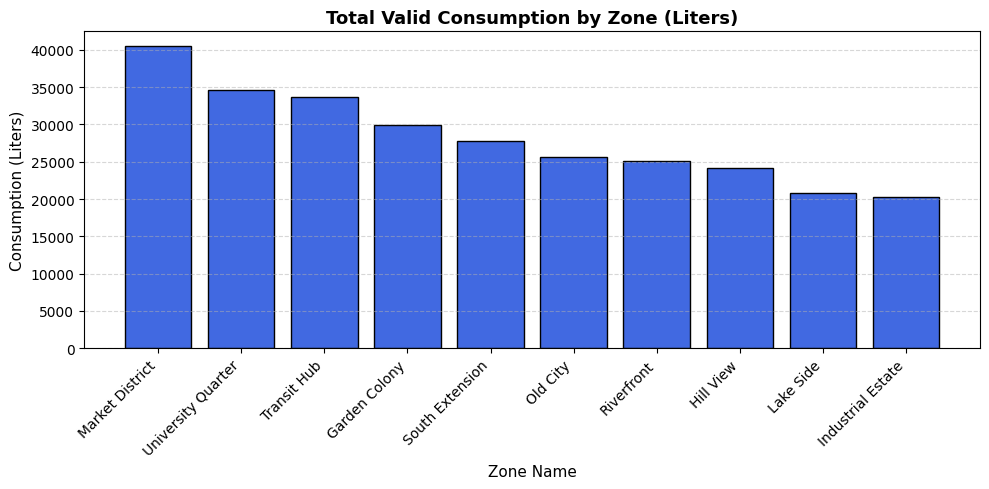

In [0]:
# 53a. Bar chart: Total Valid Consumption by Zone
import matplotlib.pyplot as plt

df_zone_bar = spark.sql("""
    SELECT z.zone_name, SUM(r.consumption_liters) AS total_consumption
    FROM water_meter_readings_source r
    JOIN water_zones z ON r.zone_id = z.zone_id
    WHERE r.reading_status = 'Valid' AND r.consumption_liters > 0
    GROUP BY z.zone_name
    ORDER BY total_consumption DESC
""").toPandas()

plt.figure(figsize=(10, 5))
plt.bar(df_zone_bar["zone_name"], df_zone_bar["total_consumption"], color="royalblue", edgecolor="black")
plt.title("Total Valid Consumption by Zone (Liters)", fontsize=13, fontweight="bold")
plt.xlabel("Zone Name", fontsize=11)
plt.ylabel("Consumption (Liters)", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

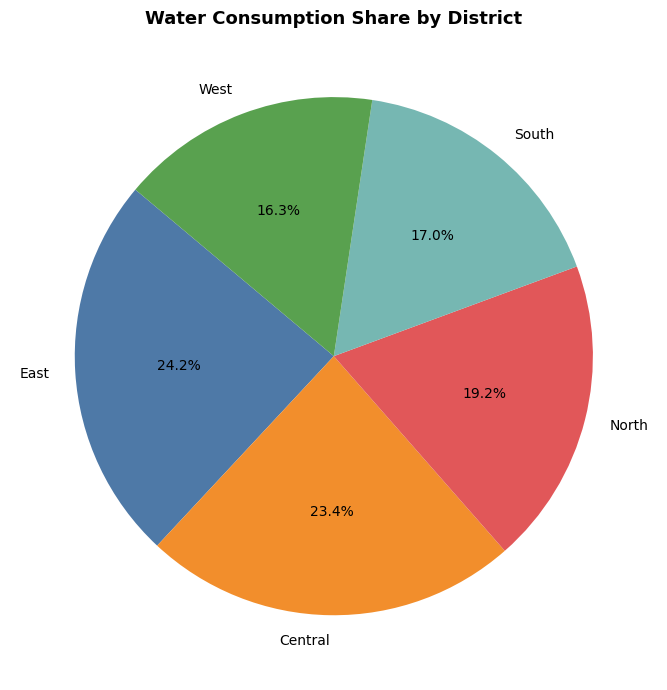

In [0]:
# 53b. Pie chart: Consumption Share by District
import matplotlib.pyplot as plt

df_district_pie = spark.sql("""
    SELECT z.district, SUM(r.consumption_liters) AS district_consumption
    FROM water_meter_readings_source r
    JOIN water_zones z ON r.zone_id = z.zone_id
    WHERE r.reading_status = 'Valid' AND r.consumption_liters > 0
    GROUP BY z.district
    ORDER BY district_consumption DESC
""").toPandas()

plt.figure(figsize=(7, 7))
plt.pie(
    df_district_pie["district_consumption"],
    labels=df_district_pie["district"],
    autopct="%1.1f%%",
    startangle=140,
    colors=["#4e79a7", "#f28e2c", "#e15759", "#76b7b2", "#59a14f"]
)
plt.title("Water Consumption Share by District", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

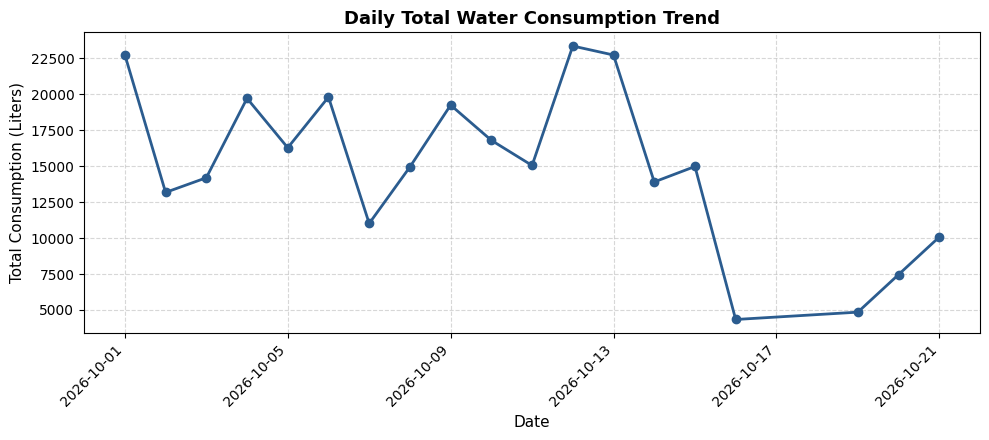

In [0]:
# 54a. Line chart: Daily Total Water Consumption
import matplotlib.pyplot as plt

df_daily_line = spark.sql("""
    SELECT CAST(reading_time AS DATE) AS reading_date,
           SUM(consumption_liters) AS daily_consumption
    FROM water_meter_readings_source
    WHERE reading_status = 'Valid' AND consumption_liters > 0
    GROUP BY CAST(reading_time AS DATE)
    ORDER BY reading_date
""").toPandas()

plt.figure(figsize=(10, 4.5))
plt.plot(df_daily_line["reading_date"], df_daily_line["daily_consumption"], marker="o", color="#2b5c8f", linewidth=2)
plt.title("Daily Total Water Consumption Trend", fontsize=13, fontweight="bold")
plt.xlabel("Date", fontsize=11)
plt.ylabel("Total Consumption (Liters)", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

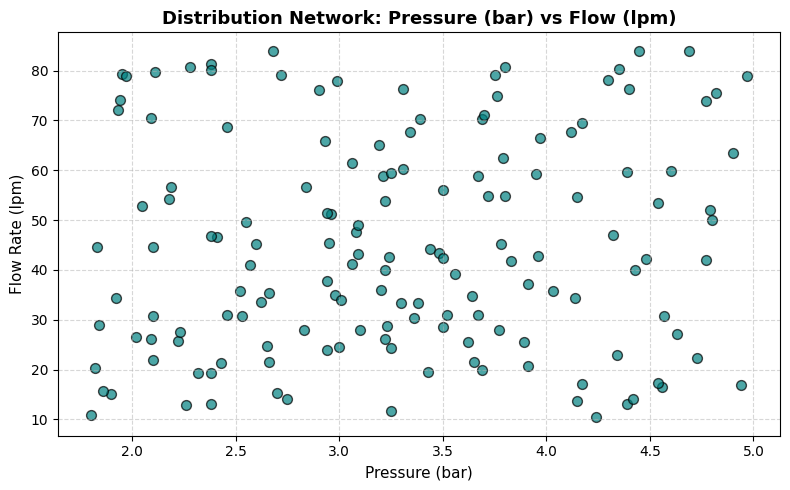

In [0]:
# 54b. Scatter plot: Pressure (bar) vs Flow (lpm)
import matplotlib.pyplot as plt

df_scatter = spark.sql("""
    SELECT pressure_bar, flow_lpm
    FROM water_meter_readings_source
    WHERE reading_status = 'Valid' AND pressure_bar IS NOT NULL AND flow_lpm IS NOT NULL
""").toPandas()

plt.figure(figsize=(8, 5))
plt.scatter(df_scatter["pressure_bar"], df_scatter["flow_lpm"], alpha=0.7, color="teal", edgecolors="k", s=50)
plt.title("Distribution Network: Pressure (bar) vs Flow (lpm)", fontsize=13, fontweight="bold")
plt.xlabel("Pressure (bar)", fontsize=11)
plt.ylabel("Flow Rate (lpm)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Final Capstone | Water Operations Analytics


In [0]:
# Final Capstone: Verification of Lakeflow Bronze-Silver-Gold pipeline outputs and operational flags
display(spark.sql("""
SELECT z.zone_name,
       z.district,
       SUM(r.consumption_liters) AS total_consumption,
       ROUND(AVG(r.pressure_bar), 2) AS avg_pressure,
       ROUND(AVG(r.chlorine_mg_l), 2) AS avg_chlorine,
       CASE WHEN AVG(r.pressure_bar) < 3.0 THEN 'Low Pressure Concern'
            WHEN AVG(r.chlorine_mg_l) < 0.5 THEN 'Low Chlorine Concern'
            ELSE 'Nominal'
       END AS operational_flag
FROM water_meter_readings_source r
JOIN water_zones z ON r.zone_id = z.zone_id
WHERE r.reading_status = 'Valid' AND r.consumption_liters > 0
GROUP BY z.zone_name, z.district
ORDER BY avg_pressure ASC
"""))
print("Final Capstone Water Operations Analytics execution completed.")


zone_name,district,total_consumption,avg_pressure,avg_chlorine,operational_flag
Transit Hub,East,33689,2.87,0.62,Low Pressure Concern
Market District,Central,40465,3.06,0.83,Nominal
Industrial Estate,South,20212,3.16,0.68,Nominal
Lake Side,West,20781,3.24,0.82,Nominal
Hill View,North,24120,3.31,0.62,Nominal
Old City,Central,25677,3.38,0.83,Nominal
Riverfront,West,25154,3.38,0.69,Nominal
Garden Colony,North,29994,3.42,0.74,Nominal
University Quarter,East,34577,3.45,0.79,Nominal
South Extension,South,27808,3.72,0.79,Nominal


Final Capstone Water Operations Analytics execution completed.
